<a href="https://colab.research.google.com/github/RupeshReddy672/DataSciencePractice/blob/master/Pandas_Exercise_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [195]:
import numpy as np
import pandas as pd

###`Q-1:` Write a program to create an empty series.

In [196]:
# code here
a = pd.Series([])


###`Q-2:` Write a Pandas program to add, subtract, multiple and divide two Pandas Series.

In [197]:
# code here
a = pd.Series(np.random.randint(10,100,12))

b = pd.Series(np.random.randint(10,100,12))

print(a+b,'\n\n')
print(a*b,'\n\n')
print(a-b,'\n\n')
print(a/b,'\n\n')

0      86
1      98
2      64
3      72
4     113
5      61
6     120
7     103
8     158
9      62
10    118
11    128
dtype: int64 


0     1173
1     1377
2     1020
3     1280
4     2640
5      748
6     2231
7     1722
8     6216
9      861
10    2640
11    3735
dtype: int64 


0    -52
1    -64
2      4
3     -8
4     47
5     27
6     74
7     61
8    -10
9    -20
10    58
11   -38
dtype: int64 


0     0.246377
1     0.209877
2     1.133333
3     0.800000
4     2.424242
5     2.588235
6     4.217391
7     3.904762
8     0.880952
9     0.512195
10    2.933333
11    0.542169
dtype: float64 




###`Q-3` Write a Pandas program to compare the elements of the two Pandas Series.
Sample Series: [2, 4, 6, 8, 10], [1, 3, 5, 7, 10]



In [198]:
# code here
a= pd.Series([2, 4, 6, 8, 10])
b= pd.Series([1, 3, 5, 7, 10])
a==b, a<b, a>b,a!=b

(0    False
 1    False
 2    False
 3    False
 4     True
 dtype: bool,
 0    False
 1    False
 2    False
 3    False
 4    False
 dtype: bool,
 0     True
 1     True
 2     True
 3     True
 4    False
 dtype: bool,
 0     True
 1     True
 2     True
 3     True
 4    False
 dtype: bool)

###`Q-5.`Write a function to change the data type of given a column or a Series. Function takes series and data type as input, returns the converted series.
```
series = pd.Series([1,2,'Python', 2.0, True, 100])
change to float type data
```
Note: Read about pd.to_numeric()

In [199]:
# code here
def change_dtype(series,dtype1):
  return pd.to_numeric(series,errors='coerce',downcast='float')


series = pd.Series([1,2,'Python', 2.0, True, 100])
change_dtype(series,float)




,0
0,1.0
1,2.0
2,NaN
3,2.0
4,1.0
5,100.0


In [200]:
def safe_change_dtype(series: pd.Series, target_dtype) -> pd.Series:
    if target_dtype in [int, float, 'int64', 'float64', 'numeric']:
        converted = pd.to_numeric(series, errors='coerce')
        return converted.astype('Int64') if target_dtype in [int, 'int64'] else converted

    elif target_dtype in ['datetime', 'datetime64[ns]']:
        return pd.to_datetime(series, errors='coerce')

    return series.astype(target_dtype)


Download data - https://drive.google.com/file/d/1LRhXwbEodeWXtzPhJCX0X9Lf_BECzvqb/view?usp=share_link
All Batsman runs series in IPL 2008 to 2022.

Below questions are based on this data.

###`Q-6` Find top 10 most run getter from the series.

In [201]:
# code here
ipl = pd.read_csv('/content/batsman_runs_ipl.csv',index_col='batter').squeeze('columns')
ipl.head()

,batsman_run
batter,
A Ashish Reddy,280
A Badoni,161
A Chandila,4
A Chopra,53
A Choudhary,25


In [202]:
ipl.sort_values(ascending=False).head(10)

,batsman_run
batter,
V Kohli,6634
S Dhawan,6244
DA Warner,5883
RG Sharma,5881
SK Raina,5536
AB de Villiers,5181
CH Gayle,4997
MS Dhoni,4978
RV Uthappa,4954


###`Q-7` No of players having runs above 3000

In [203]:
# code here
ipl[ipl>3000].count()

np.int64(20)

###`Q-8` No of players having runs above mean value?

In [204]:
# code here
ipl[ipl>ipl.mean()].count()

np.int64(128)

Download data - https://drive.google.com/file/d/1QZuZ5bypUInfVvarHACLAi8tXXHvb8xd/view?usp=share_link

file name - items.csv



###`Q-9`
    i. Read `items.csv` making `item_name` as index.
    ii. Show no of nan values
    ii. Item price is given in $, so convert it to rupees without currency symbol.
    iii. Make data type of newly made series as float.
    iv. Fill nan with mean of the series


How csv file looks

```
item_name	item_price
Chips and Fresh Tomato Salsa	$2.39
Izze	$3.39
Nantucket Nectar	$3.39
Chips and Tomatillo-Green Chili Salsa	$2.39
Chicken Bowl	$16.98

```

In [205]:
# code here
#1
items = pd.read_csv('/content/items.csv',index_col='item_name').squeeze()
print(items.head())


item_name
Chips and Fresh Tomato Salsa              $2.39 
Izze                                      $3.39 
Nantucket Nectar                          $3.39 
Chips and Tomatillo-Green Chili Salsa     $2.39 
Chicken Bowl                             $16.98 
Name: item_price, dtype: object


In [206]:
#2 Show no of nan values
items.isnull().sum()

np.int64(50)

In [207]:
items.head(10)

,item_price
item_name,
Chips and Fresh Tomato Salsa,$2.39
Izze,$3.39
Nantucket Nectar,$3.39
Chips and Tomatillo-Green Chili Salsa,$2.39
Chicken Bowl,$16.98
Chicken Bowl,$10.98
Side of Chips,NaN
Steak Burrito,$11.75
Steak Soft Tacos,NaN


In [208]:
items = items.str.replace('$', '', regex=False)
items = items.astype(float)



In [209]:
items = np.round(items*(94.07),2)
items

,item_price
item_name,
Chips and Fresh Tomato Salsa,224.83
Izze,318.90
Nantucket Nectar,318.90
Chips and Tomatillo-Green Chili Salsa,224.83
Chicken Bowl,1597.31
...,...
Steak Burrito,1105.32
Steak Burrito,1105.32
Chicken Salad Bowl,1058.29


In [210]:
#method 2
#ii. Item price is given in $, so convert it to rupees without currency symbol.
df = pd.read_csv('items.csv')
df['item_price'] = np.round(df['item_price'].str.replace('$','').astype(float)*(94.07),2)


In [211]:
df

,item_name,item_price
0,Chips and Fresh Tomato Salsa,224.83
1,Izze,318.90
2,Nantucket Nectar,318.90
3,Chips and Tomatillo-Green Chili Salsa,224.83
4,Chicken Bowl,1597.31
...,...,...
4617,Steak Burrito,1105.32
4618,Steak Burrito,1105.32
4619,Chicken Salad Bowl,1058.29
4620,Chicken Salad Bowl,823.11


In [212]:
#iii. Make data type of newly made series as float.
items = items.astype(float)
items.dtype

dtype('float64')

In [213]:
#v. Fill nan with mean of the series
f = np.round(items.mean(),2)
items.fillna(f,inplace=True)



In [214]:
items

,item_price
item_name,
Chips and Fresh Tomato Salsa,224.83
Izze,318.90
Nantucket Nectar,318.90
Chips and Tomatillo-Green Chili Salsa,224.83
Chicken Bowl,1597.31
...,...
Steak Burrito,1105.32
Steak Burrito,1105.32
Chicken Salad Bowl,1058.29


###`Q-10`:
    i. Find mean price
    ii. Find 30th and 6th percentile value
    iii. Plot Histogram on price with bin size 50
    iv. No of items price lies between [1000 to 2000]



In [215]:
items.sort_values()

,item_price
item_name,
Bottled Water,102.54
Canned Soda,102.54
Canned Soda,102.54
Canned Soda,102.54
Canned Soda,102.54
...,...
Veggie Burrito,3174.86
Chicken Burrito,3292.45
Chicken Burrito,3292.45


702.05
418.61
117.59


np.int64(1066)

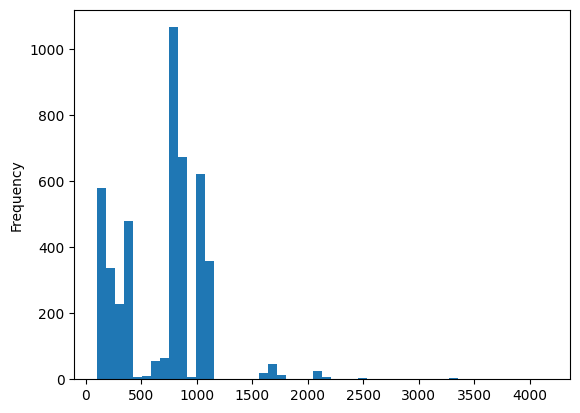

In [216]:
# code here
#1
print(np.round(items.mean(),2))
#2
print(np.percentile(items,30))
print(np.percentile(items,6))
items.plot(kind='hist',bins=50)
items.between(1000,2000).sum()